# Stroke Risk Prediction



## 1. Setup and data read-in

In [78]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


RANDOM_STATE = 42
DATA_PATH = Path("src_stroke_prediction.csv")


### Read in and quick QA

In [79]:
df = pd.read_csv(DATA_PATH, na_values=["N/A", "NA", ""])
df["bmi"] = pd.to_numeric(df["bmi"], errors="coerce")

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
display(df.head())
display(df.dtypes.rename("dtype").to_frame())


Rows: 5,110
Columns: 12


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


,dtype
id,int64
gender,str
age,float64
hypertension,int64
heart_disease,int64
ever_married,str
work_type,str
Residence_type,str
avg_glucose_level,float64
bmi,float64


### Quick DQ

In [80]:
target_rate = df["stroke"].mean()
missing = (
    df.isna()
    .sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_rate=lambda x: x["missing_count"] / len(df))
    .query("missing_count > 0")
)
summary = {
    "rows": int(df.shape[0]),
    "columns": int(df.shape[1]),
    "stroke_positive": int(df["stroke"].sum()),
    "stroke_rate": float(target_rate),
    "bmi_missing": int(df["bmi"].isna().sum()),
    "duplicate_id_count": int(df["id"].duplicated().sum()),
}

print(json.dumps(summary, indent=2))
display(missing)


{
  "rows": 5110,
  "columns": 12,
  "stroke_positive": 249,
  "stroke_rate": 0.0487279843444227,
  "bmi_missing": 201,
  "duplicate_id_count": 0
}


,missing_count,missing_rate
bmi,201,0.039335


### Chapter 1 parking lot

- id may need to be further data masking from data governance and hipaa pov.
- clearify definition of '0' 'otherwise'
- | `stroke` | **Target:** 1 if the patient had a stroke, 0 otherwise |

## 2. Exploratory data analysis

### Target balance

,stroke,count,proportion
0,0,4861,0.951272
1,1,249,0.048728


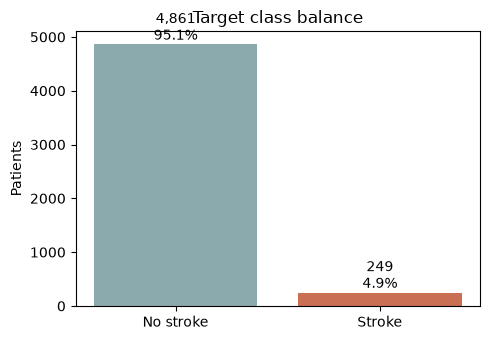

In [81]:
target_balance = (
    df["stroke"]
    .value_counts()
    .sort_index()
    .rename_axis("stroke")
    .reset_index(name="count")
)
target_balance["proportion"] = target_balance["count"] / len(df)
display(target_balance)

fig, ax = plt.subplots(figsize=(5, 3.5))
labels = ["No stroke", "Stroke"]
ax.bar(labels, target_balance["count"], color=["#8BAAAD", "#C96F53"])
ax.set_title("Target class balance")
ax.set_ylabel("Patients")
for i, row in target_balance.iterrows():
    label = f"{int(row['count']):,}\n{row['proportion']:.1%}"
    ax.text(i, row["count"], label, ha="center", va="bottom")
plt.tight_layout()
plt.show()


### Categorical variables

For categorical variables, I add a chi-square test to get an idea on the impact.


Stroke rate by gender


,patients,patient_proportion,strokes,stroke_rate
gender,,,,
Male,2115,0.413894,108,0.051064
Female,2994,0.585910,141,0.047094
Other,1,0.000196,0,0.000000


Chi-square test p-value: 0.7895


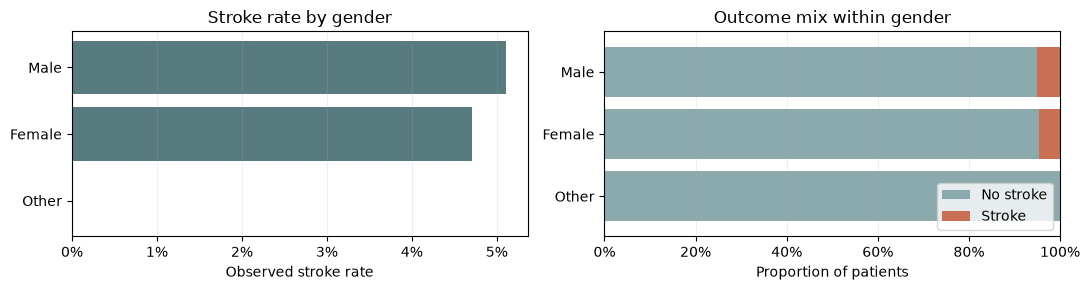


Stroke rate by ever_married


,patients,patient_proportion,strokes,stroke_rate
ever_married,,,,
Yes,3353,0.656164,220,0.065613
No,1757,0.343836,29,0.016505


Chi-square test p-value: 1.639e-14


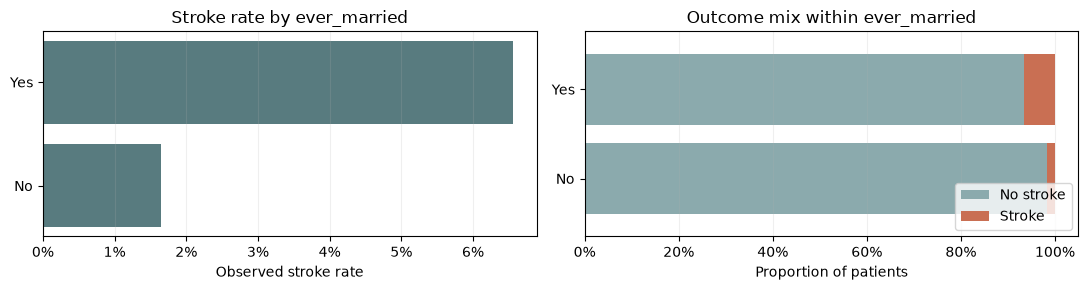


Stroke rate by work_type


,patients,patient_proportion,strokes,stroke_rate
work_type,,,,
Self-employed,819,0.160274,65,0.079365
Private,2925,0.572407,149,0.050940
Govt_job,657,0.128571,33,0.050228
children,687,0.134442,2,0.002911
Never_worked,22,0.004305,0,0.000000


Chi-square test p-value: 5.398e-10


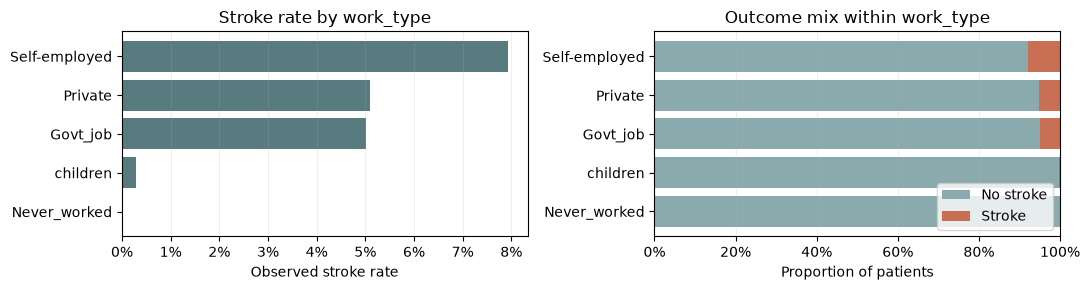


Stroke rate by Residence_type


,patients,patient_proportion,strokes,stroke_rate
Residence_type,,,,
Urban,2596,0.508023,135,0.052003
Rural,2514,0.491977,114,0.045346


Chi-square test p-value: 0.2983


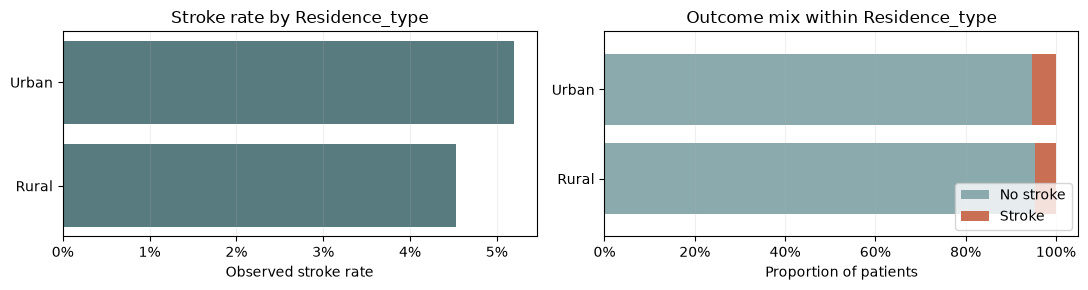


Stroke rate by smoking_status


,patients,patient_proportion,strokes,stroke_rate
smoking_status,,,,
formerly smoked,885,0.173190,70,0.079096
smokes,789,0.154403,42,0.053232
never smoked,1892,0.370254,90,0.047569
Unknown,1544,0.302153,47,0.030440


Chi-square test p-value: 2.085e-06


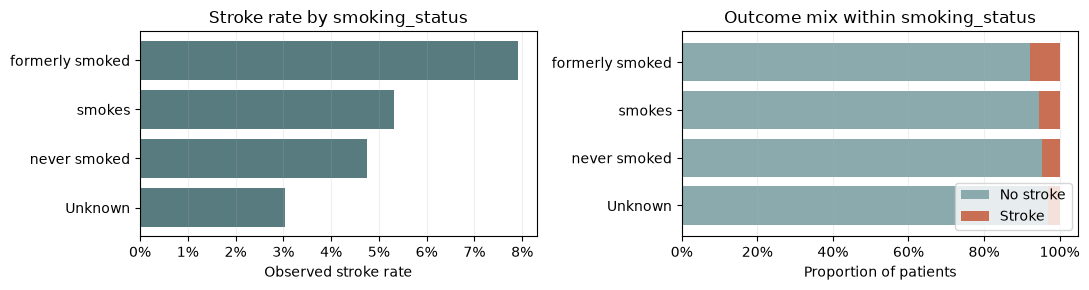


Stroke rate by hypertension


,patients,patient_proportion,strokes,stroke_rate
hypertension,,,,
1,498,0.097456,66,0.132530
0,4612,0.902544,183,0.039679


Chi-square test p-value: 1.662e-19


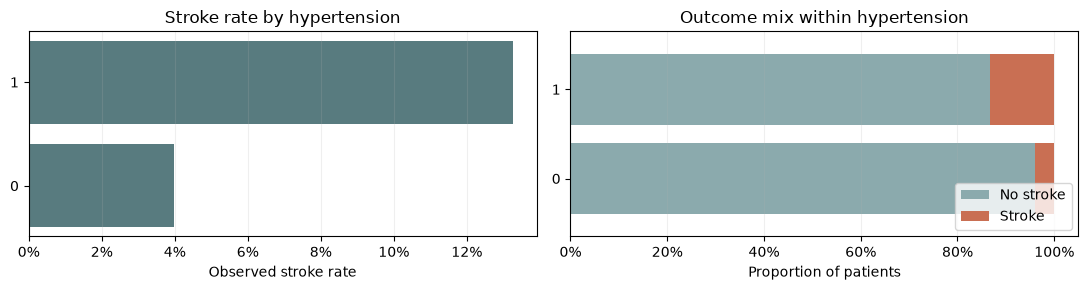


Stroke rate by heart_disease


,patients,patient_proportion,strokes,stroke_rate
heart_disease,,,,
1,276,0.054012,47,0.170290
0,4834,0.945988,202,0.041787


Chi-square test p-value: 2.089e-21


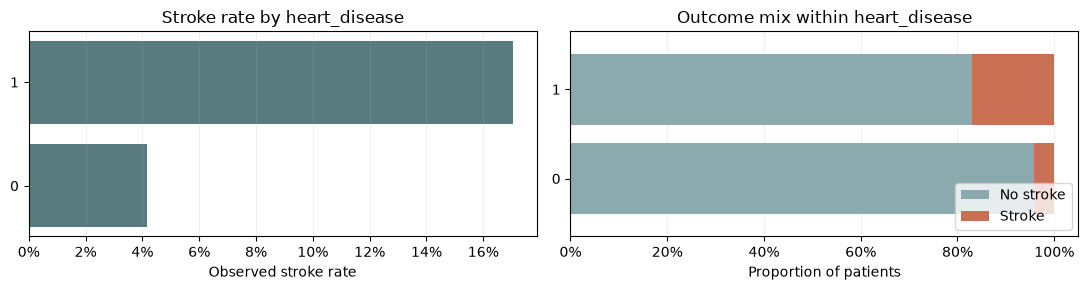

,check,count
0,duplicate ids,0
1,missing bmi,201
2,gender value Other,1
3,unknown smoking status,1544


In [82]:
def stroke_rate_table(data, column):
    out = (
        data.groupby(column, dropna=False)
        .agg(patients=("stroke", "size"), strokes=("stroke", "sum"), stroke_rate=("stroke", "mean"))
        .assign(patient_proportion=lambda x: x["patients"] / len(data))
        .sort_values("stroke_rate", ascending=False)
    )
    return out[["patients", "patient_proportion", "strokes", "stroke_rate"]]

from scipy.stats import chi2_contingency

categorical_cols = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status",
    "hypertension",
    "heart_disease",
]

eda_tables = {col: stroke_rate_table(df, col) for col in categorical_cols}

for name, table in eda_tables.items():
    print(f"\nStroke rate by {name}")
    display(table)

    contingency = pd.crosstab(df[name].fillna("Missing"), df["stroke"])
    chi2, p_value, dof, expected = chi2_contingency(contingency)
    print(f"Chi-square test p-value: {p_value:.4g}")

    fig, axes = plt.subplots(1, 2, figsize=(11, max(3, 0.35 * len(table))))

    rate_plot = table.sort_values("stroke_rate")
    axes[0].barh(rate_plot.index.astype(str), rate_plot["stroke_rate"], color="#587B7F")
    axes[0].set_title(f"Stroke rate by {name}")
    axes[0].set_xlabel("Observed stroke rate")
    axes[0].xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
    axes[0].grid(axis="x", alpha=0.2)

    prop_plot = pd.crosstab(df[name].fillna("Missing"), df["stroke"], normalize="index")
    prop_plot = prop_plot.rename(columns={0: "No stroke", 1: "Stroke"}).sort_values("Stroke")
    prop_plot[["No stroke", "Stroke"]].plot(
        kind="barh",
        stacked=True,
        color=["#8BAAAD", "#C96F53"],
        ax=axes[1],
        width=0.8,
    )
    axes[1].set_title(f"Outcome mix within {name}")
    axes[1].set_xlabel("Proportion of patients")
    axes[1].set_ylabel("")
    axes[1].xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
    axes[1].legend(loc="lower right")
    axes[1].grid(axis="x", alpha=0.2)

    plt.tight_layout()
    plt.show()

quality_checks = pd.DataFrame(
    {
        "check": [
            "duplicate ids",
            "missing bmi",
            "gender value Other",
            "unknown smoking status",
        ],
        "count": [
            df["id"].duplicated().sum(),
            df["bmi"].isna().sum(),
            (df["gender"] == "Other").sum(),
            (df["smoking_status"] == "Unknown").sum(),
        ],
    }
)
display(quality_checks)


### Continuous variables
For the numeric fields, I could also use bins here and look at summary stats plus distribution curves.

,count,mean,std,median,min,max
age,5110.0,43.226614,22.612647,45.000,0.08,82.00
avg_glucose_level,5110.0,106.147677,45.283560,91.885,55.12,271.74
bmi,4909.0,28.893237,7.854067,28.100,10.30,97.60


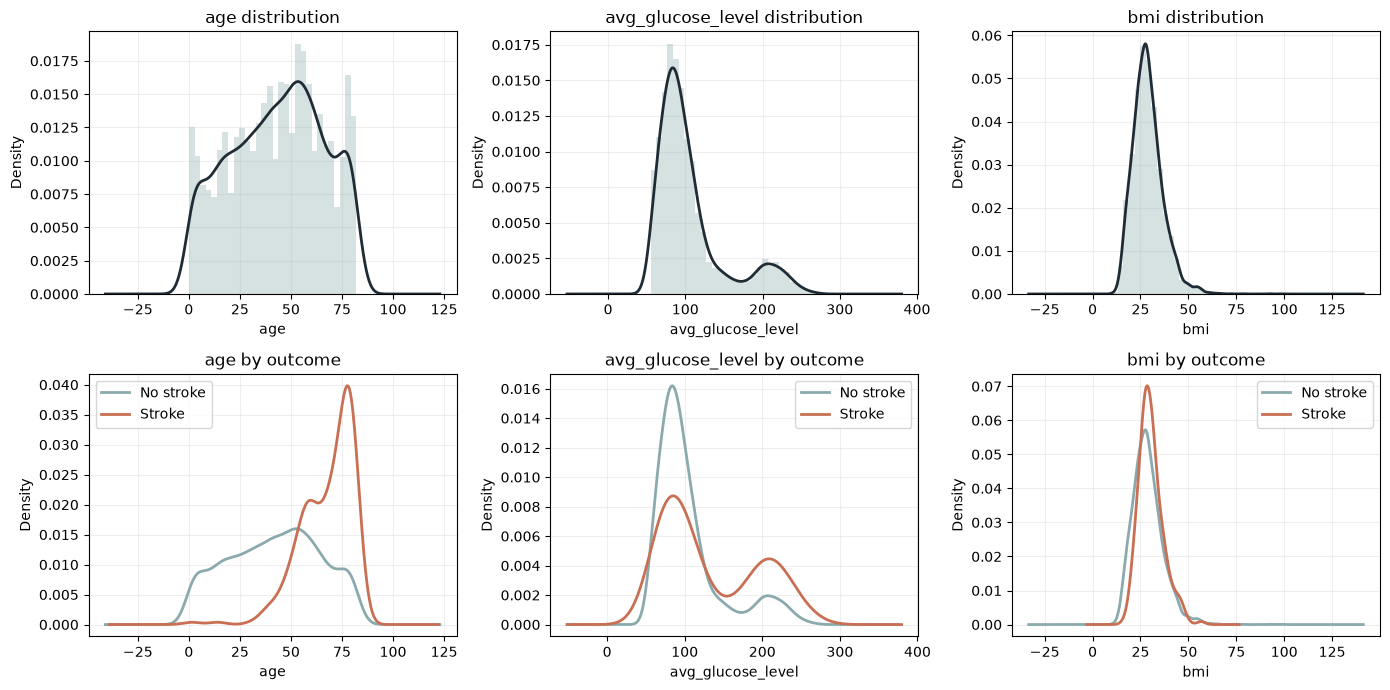

In [83]:
numeric_cols = ["age", "avg_glucose_level", "bmi"]
continuous_summary = df[numeric_cols].agg(["count", "mean", "std", "median", "min", "max"]).T
display(continuous_summary)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes[0], numeric_cols):
    df[col].dropna().plot(kind="hist", bins=30, density=True, alpha=0.35, color="#8BAAAD", ax=ax)
    df[col].dropna().plot(kind="density", color="#1F2C36", linewidth=2, ax=ax)
    ax.set_title(f"{col} distribution")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
    ax.grid(alpha=0.2)

for ax, col in zip(axes[1], numeric_cols):
    for stroke_value, label, color in [(0, "No stroke", "#8BAAAD"), (1, "Stroke", "#C96F53")]:
        df.loc[df["stroke"] == stroke_value, col].dropna().plot(
            kind="density", ax=ax, label=label, color=color, linewidth=2
        )
    ax.set_title(f"{col} by outcome")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()


### Continuous variables by outcome
I also look at the numeric fields by outcome with boxplots.

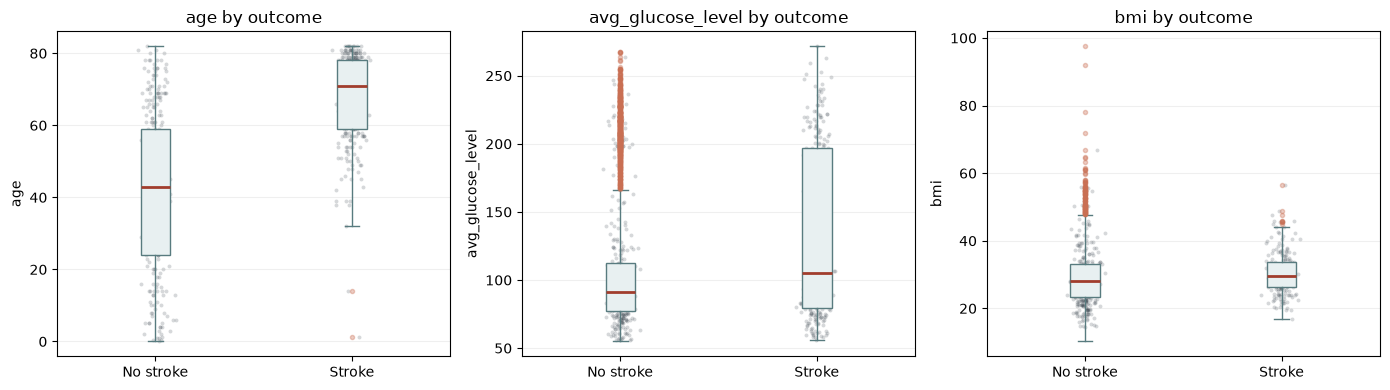

In [84]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
outcome_labels = {0: "No stroke", 1: "Stroke"}

for ax, col in zip(axes, numeric_cols):
    plot_df = df[["stroke", col]].dropna().copy()
    plot_df["outcome"] = plot_df["stroke"].map(outcome_labels)

    values_by_group = [
        plot_df.loc[plot_df["stroke"] == value, col]
        for value in [0, 1]
    ]
    ax.boxplot(
        values_by_group,
        tick_labels=[outcome_labels[0], outcome_labels[1]],
        patch_artist=True,
        boxprops={"facecolor": "#E8F0F1", "color": "#587B7F"},
        medianprops={"color": "#A13D2D", "linewidth": 2},
        whiskerprops={"color": "#587B7F"},
        capprops={"color": "#587B7F"},
        flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "#C96F53", "markeredgecolor": "#C96F53", "alpha": 0.35},
    )

    rng = np.random.default_rng(RANDOM_STATE)
    for pos, values in enumerate(values_by_group, start=1):
        sample = values.sample(min(len(values), 300), random_state=RANDOM_STATE)
        jitter = rng.normal(0, 0.035, size=len(sample))
        ax.scatter(
            np.full(len(sample), pos) + jitter,
            sample,
            s=8,
            alpha=0.18,
            color="#1F2C36",
            linewidths=0,
        )

    ax.set_title(f"{col} by outcome")
    ax.set_xlabel("")
    ax.set_ylabel(col)
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


### EDA takeaways

- Stroke positives are rare at about 5% of patients, so the model should optimize ranking quality and outreach yield rather than accuracy.
- Age shows the clearest relationship with stroke risk.
- Heart disease, hypertension, and high glucose are clinically plausible risk signals and appear useful in the extract.
- BMI has missing values that should be imputed inside the training pipeline.
- `Unknown` smoking status is common. I keep it as its own category because it may carry information about data collection as well as patient behavior.

### Chapter 2 parking lot

- Investigate BMI missingness and test better imputation than a simple median.
- Spend more time comparing stroke vs non-stroke distributions for the continuous variables.
- Run quick one-variable regressions against stroke to check whether each numeric relationship looks roughly linear.
- Test a small set of interaction effects, especially age with hypertension, heart disease, and glucose.
- Create an `Other` gender category instead of dropping the one non Male/Female record.


## 3. Preprocessing and split

### Modeling fields
This cell keeps the feature choices visible before any modeling code runs.

In [85]:
target = "stroke"
identifier = "id"

numeric_features = ["age", "avg_glucose_level", "bmi", "hypertension", "heart_disease"]
categorical_features = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
feature_cols = numeric_features + categorical_features

print("Features used:", feature_cols)
print("Identifier excluded:", identifier)


Features used: ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease', 'gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
Identifier excluded: id


### Small cleaning choices
I only make two categorical cleanups here: drop the one non Male/Female gender record for this quick analysis, and combine `children` with `Never_worked` because both represent patients outside the workforce and aviod .

In [86]:
model_df = df.copy()
starting_rows = len(model_df)

model_df = model_df[model_df["gender"].isin(["Male", "Female"])].copy()
removed_gender_rows = starting_rows - len(model_df)

model_df["work_type"] = model_df["work_type"].replace(
    {"children": "Not_working", "Never_worked": "Not_working"}
)

cleaning_summary = pd.DataFrame(
    {
        "step": [
            "source rows",
            "rows after gender filter",
            "removed non Male/Female gender rows",
            "work_type levels after merge",
        ],
        "result": [
            starting_rows,
            len(model_df),
            removed_gender_rows,
            ", ".join(sorted(model_df["work_type"].unique())),
        ],
    }
)
display(cleaning_summary)


,step,result
0,source rows,5110
1,rows after gender filter,5109
2,removed non Male/Female gender rows,1
3,work_type levels after merge,"Govt_job, Not_working, Private, Self-employed"


### Split first, then impute BMI
BMI has missing values, so I fill it after the split. I use the training-set BMI mean for training rows and the test-set BMI mean for test rows, avoiding one shared grand average.

In [87]:
X = model_df[feature_cols].copy()
y = model_df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

bmi_impute_summary = pd.DataFrame(
    {
        "split": ["train", "test"],
        "missing_before": [X_train["bmi"].isna().sum(), X_test["bmi"].isna().sum()],
        "mean_used": [X_train["bmi"].mean(), X_test["bmi"].mean()],
    }
)

X_train["bmi"] = X_train["bmi"].fillna(X_train["bmi"].mean())
X_test["bmi"] = X_test["bmi"].fillna(X_test["bmi"].mean())

bmi_impute_summary["missing_after"] = [X_train["bmi"].isna().sum(), X_test["bmi"].isna().sum()]
bmi_impute_summary["mean_used"] = bmi_impute_summary["mean_used"].round(2)
display(bmi_impute_summary)


,split,missing_before,mean_used,missing_after
0,train,163,28.88,0
1,test,38,28.94,0


### Model preprocessing
At this point BMI is filled, so the pipeline only needs to scale numeric fields and one-hot encode categorical fields.

In [88]:
numeric_transformer = Pipeline(
    steps=[("scaler", StandardScaler())]
)

categorical_transformer = Pipeline(
    steps=[("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True))]
)

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

split_summary = pd.DataFrame(
    {
        "split": ["train", "test"],
        "patients": [len(y_train), len(y_test)],
        "strokes": [int(y_train.sum()), int(y_test.sum())],
        "stroke_rate": [float(y_train.mean()), float(y_test.mean())],
    }
)
display(split_summary)


,split,patients,strokes,stroke_rate
0,train,4087,199,0.048691
1,test,1022,50,0.048924


### Chapter 3 parking lot

- Adding a validation set
- k fold validation 


## 4. Logistic regression models

I pick lr model as the baseline model

### Variable-selection check
Quick check some assumptions for the logistic regressoin model.

,age,avg_glucose_level,bmi,hypertension,heart_disease
age,1.000000,0.231130,0.324306,0.266940,0.272665
avg_glucose_level,0.231130,1.000000,0.158748,0.170802,0.162378
bmi,0.324306,0.158748,1.000000,0.165833,0.036683
hypertension,0.266940,0.170802,0.165833,1.000000,0.097626
heart_disease,0.272665,0.162378,0.036683,0.097626,1.000000


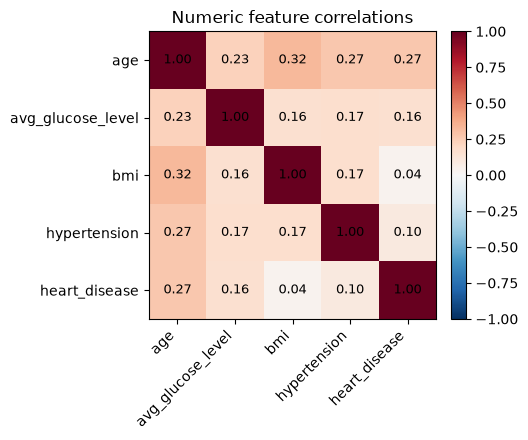

,patients,mean_age,median_age,stroke_rate
ever_married,,,,
No,1390,21.716576,18.0,0.016547
Yes,2697,54.362254,54.0,0.065258


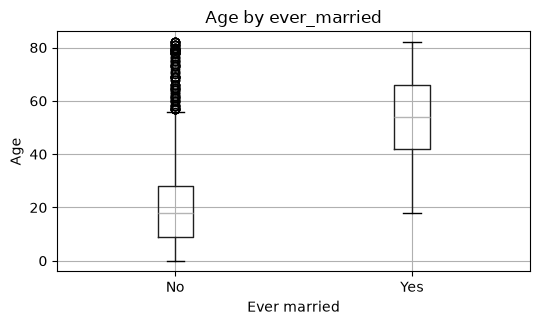

In [89]:
numeric_corr = X_train[numeric_features].corr()
display(numeric_corr)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(numeric_corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_features)))
ax.set_yticks(range(len(numeric_features)))
ax.set_xticklabels(numeric_features, rotation=45, ha="right")
ax.set_yticklabels(numeric_features)
ax.set_title("Numeric feature correlations")
for i in range(len(numeric_features)):
    for j in range(len(numeric_features)):
        ax.text(j, i, f"{numeric_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

age_by_marriage = (
    pd.concat([X_train, y_train.rename("stroke")], axis=1)
    .groupby("ever_married")
    .agg(
        patients=("stroke", "size"),
        mean_age=("age", "mean"),
        median_age=("age", "median"),
        stroke_rate=("stroke", "mean"),
    )
)
display(age_by_marriage)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
X_train.boxplot(column="age", by="ever_married", ax=ax)
ax.set_title("Age by ever_married")
ax.figure.suptitle("")
ax.set_xlabel("Ever married")
ax.set_ylabel("Age")
plt.tight_layout()
plt.show()


### Fit unweighted and weighted models
In addition to unweighted model, I pick weighted model because stroke is a rare event(~5%). Both models use the same preprocessing pipeline. The only difference is whether logistic regression uses `class_weight="balanced"`.

In [90]:
def make_logistic_model(class_weight=None):
    return Pipeline(
        steps=[
            ("preprocess", preprocess),
            (
                "model",
                LogisticRegression(
                    solver="liblinear",
                    class_weight=class_weight,
                    max_iter=5000,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )

unweighted_model = make_logistic_model(class_weight=None)
weighted_model = make_logistic_model(class_weight="balanced")

unweighted_model.fit(X_train, y_train)
weighted_model.fit(X_train, y_train)

unweighted_proba = unweighted_model.predict_proba(X_test)[:, 1]
weighted_proba = weighted_model.predict_proba(X_test)[:, 1]

model_scores = {
    "Unweighted logistic": (unweighted_model, unweighted_proba),
    "Weighted logistic": (weighted_model, weighted_proba),
}


### Evaluation at an outreach threshold
For classification metrics, I use a top 10% threshold. That matches the outreach use case better than a default 0.50 cutoff because coordinators can only call a limited group.

In [91]:
from sklearn.metrics import brier_score_loss, f1_score, roc_curve
from sklearn.calibration import calibration_curve

CHOSEN_FRACTION = 0.10

def threshold_for_top_fraction(scores, fraction=CHOSEN_FRACTION):
    k = max(1, int(np.ceil(len(scores) * fraction)))
    return np.sort(scores)[::-1][k - 1]

def outreach_at_fraction(y_true, scores, fraction):
    n = len(y_true)
    k = max(1, int(np.ceil(n * fraction)))
    order = np.argsort(scores)[::-1]
    selected = order[:k]
    selected_true = np.asarray(y_true)[selected]
    true_positives = int(selected_true.sum())
    false_positives = int(k - true_positives)
    total_positives = int(np.asarray(y_true).sum())
    return {
        "cutoff": f"Top {int(fraction * 100)}%",
        "patients_called": int(k),
        "true_strokes_reached": true_positives,
        "false_positives": false_positives,
        "precision": true_positives / k,
        "recall": true_positives / total_positives if total_positives else np.nan,
        "min_score": float(scores[selected[-1]]),
    }

def evaluate_model(name, scores, fraction=CHOSEN_FRACTION):
    threshold = threshold_for_top_fraction(scores, fraction)
    preds = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    f1 = f1_score(y_test, preds, zero_division=0)
    top10 = outreach_at_fraction(y_test.to_numpy(), scores, fraction)
    return {
        "model": name,
        "chosen_threshold": threshold,
        "roc_auc": roc_auc_score(y_test, scores),
        "pr_auc": average_precision_score(y_test, scores),
        "sensitivity": sensitivity,
        "specificity": specificity,
        "precision": precision,
        "f1": f1,
        "brier_score": brier_score_loss(y_test, scores),
        "top10_precision": top10["precision"],
        "top10_recall": top10["recall"],
        "top10_true_strokes_reached": top10["true_strokes_reached"],
    }

metrics = pd.DataFrame(
    [evaluate_model(name, scores) for name, (_, scores) in model_scores.items()]
).sort_values(["pr_auc", "top10_recall"], ascending=False)

display(metrics)

best_model_name = metrics.iloc[0]["model"]
best_model, best_scores = model_scores[best_model_name]
print(f"Recommended model by held-out PR AUC: {best_model_name}")


,model,chosen_threshold,roc_auc,pr_auc,sensitivity,specificity,precision,f1,brier_score,top10_precision,top10_recall,top10_true_strokes_reached
0,Unweighted logistic,0.150286,0.839074,0.266666,0.52,0.920782,0.252427,0.339869,0.040781,0.252427,0.52,26
1,Weighted logistic,0.799920,0.839321,0.258072,0.48,0.918724,0.233010,0.313725,0.172748,0.233010,0.48,24


Recommended model by held-out PR AUC: Unweighted logistic


### Discrimination curves
ROC-AUC shows overall ranking quality, while PR-AUC is more informative here because stroke is rare.

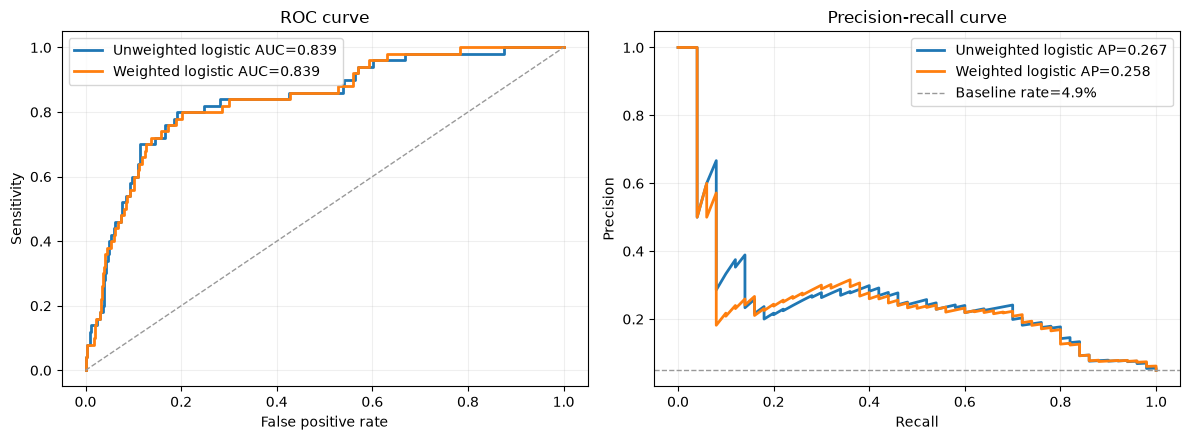

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name, (_, scores) in model_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    axes[0].plot(fpr, tpr, label=f"{name} AUC={roc_auc_score(y_test, scores):.3f}", linewidth=2)

axes[0].plot([0, 1], [0, 1], color="#999999", linestyle="--", linewidth=1)
axes[0].set_title("ROC curve")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("Sensitivity")
axes[0].legend()
axes[0].grid(alpha=0.2)

for name, (_, scores) in model_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    axes[1].plot(recall, precision, label=f"{name} AP={average_precision_score(y_test, scores):.3f}", linewidth=2)

axes[1].axhline(y_test.mean(), color="#999999", linestyle="--", linewidth=1, label=f"Baseline rate={y_test.mean():.1%}")
axes[1].set_title("Precision-recall curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()


### Probability quality
Brier score summarizes probability error. The calibration plot checks whether predicted risk roughly lines up with observed stroke rate.

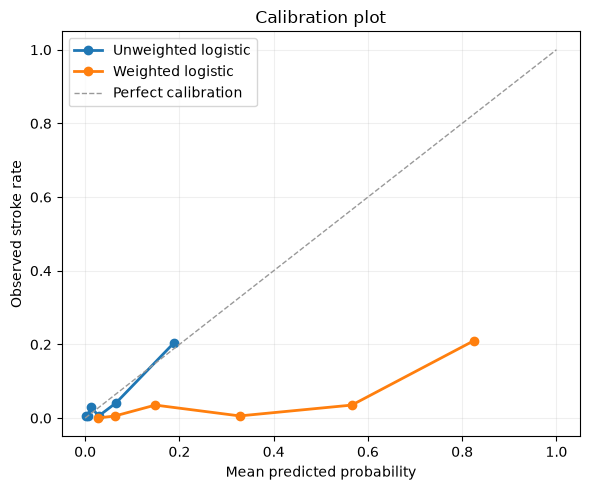

,model,brier_score
0,Unweighted logistic,0.040781
1,Weighted logistic,0.172748


In [93]:
fig, ax = plt.subplots(figsize=(6, 5))

for name, (_, scores) in model_scores.items():
    frac_pos, mean_pred = calibration_curve(y_test, scores, n_bins=6, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", linewidth=2, label=name)

ax.plot([0, 1], [0, 1], color="#999999", linestyle="--", linewidth=1, label="Perfect calibration")
ax.set_title("Calibration plot")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed stroke rate")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

brier_table = metrics[["model", "brier_score"]].sort_values("brier_score")
display(brier_table)


### Categorical association checks
Before the odds-ratio table, I do a quick unadjusted chi-square check for the categorical variables. This is only a screening view; the odds-ratio table below is the main interpretation table because it adjusts for the other fields.

In [94]:
def clean_feature_name(name):
    if name in numeric_features:
        return name
    for col in categorical_features:
        prefix = f"{col}_"
        if name.startswith(prefix):
            level = name.replace(prefix, "", 1)
            return f"{col}[{level}]"
    return name

categorical_tests = []
for col in categorical_features:
    contingency = pd.crosstab(X_train[col], y_train)
    chi2_stat, p_value, dof, expected = chi2_contingency(contingency)
    categorical_tests.append(
        {
            "variable": col,
            "chi_square": chi2_stat,
            "degrees_of_freedom": dof,
            "p_value": p_value,
        }
    )

categorical_tests = pd.DataFrame(categorical_tests).sort_values("p_value")
display(categorical_tests)


,variable,chi_square,degrees_of_freedom,p_value
1,ever_married,45.940859,1,1.218773e-11
2,work_type,44.115542,3,1.426255e-09
4,smoking_status,22.838138,3,4.364476e-05
3,Residence_type,1.184990,1,2.763424e-01
0,gender,0.386465,1,5.341636e-01


### Odds ratios
For this table, categorical variables use one reference level. Odds ratios above 1 mean higher odds of stroke relative to the reference or per one-unit increase for numeric fields.

In [95]:
from scipy.optimize import minimize
from scipy.stats import norm, chi2_contingency

reference_levels = {
    col: sorted(X_train[col].dropna().unique())[0]
    for col in categorical_features
}
reference_table = pd.DataFrame(
    {"variable": list(reference_levels.keys()), "reference_level": list(reference_levels.values())}
)
display(reference_table)

X_infer = pd.get_dummies(
    X_train[feature_cols],
    columns=categorical_features,
    drop_first=True,
    dtype=float,
)
X_infer = X_infer.astype(float)
y_infer = y_train.to_numpy(dtype=float)
X_mat = np.column_stack([np.ones(len(X_infer)), X_infer.to_numpy()])

# Fit a plain logistic regression for interpretable standard errors.
def nll(beta):
    z = X_mat @ beta
    return np.sum(np.logaddexp(0, z) - y_infer * z)

def grad(beta):
    z = X_mat @ beta
    p = 1 / (1 + np.exp(-z))
    return X_mat.T @ (p - y_infer)

result = minimize(nll, np.zeros(X_mat.shape[1]), jac=grad, method="BFGS", options={"maxiter": 1000})
beta = result.x
p_hat = 1 / (1 + np.exp(-(X_mat @ beta)))
weights = p_hat * (1 - p_hat)
hessian = X_mat.T @ (weights[:, None] * X_mat)
cov = np.linalg.pinv(hessian)
se = np.sqrt(np.diag(cov))
wald_z = beta / se
wald_chi_square = wald_z ** 2
p_values = 2 * (1 - norm.cdf(np.abs(wald_z)))

terms = ["intercept"] + list(X_infer.columns)
or_table = pd.DataFrame(
    {
        "term": terms,
        "coefficient": beta,
        "std_error": se,
        "wald_chi_square": wald_chi_square,
        "p_value": p_values,
        "odds_ratio": np.exp(beta),
        "ci_95_low": np.exp(beta - 1.96 * se),
        "ci_95_high": np.exp(beta + 1.96 * se),
    }
)

or_table["term"] = or_table["term"].map(clean_feature_name)
or_table = or_table.loc[or_table["term"] != "intercept"].sort_values("p_value")
display(or_table.head(20))

if not result.success:
    print("Note: the inference model did not fully converge, so treat odds-ratio p-values cautiously.")


,variable,reference_level
0,gender,Female
1,ever_married,No
2,work_type,Govt_job
3,Residence_type,Rural
4,smoking_status,Unknown


,term,coefficient,std_error,wald_chi_square,p_value,odds_ratio,ci_95_low,ci_95_high
1,age,0.073421,0.006467,128.891075,0.000000,1.076184,1.062629,1.089912
2,avg_glucose_level,0.004105,0.001341,9.374827,0.002200,1.004114,1.001478,1.006756
4,hypertension,0.511545,0.183274,7.790477,0.005252,1.667866,1.164541,2.388733
7,ever_married[Yes],-0.261175,0.250770,1.084707,0.297647,0.770146,0.471100,1.259021
10,work_type[Self-employed],-0.235623,0.254534,0.856923,0.354601,0.790079,0.479740,1.301171
14,smoking_status[smokes],0.186621,0.258733,0.520256,0.470733,1.205170,0.725789,2.001182
13,smoking_status[never smoked],-0.156678,0.220290,0.505857,0.476938,0.854979,0.555189,1.316650
5,heart_disease,0.152127,0.214411,0.503404,0.478008,1.164308,0.764817,1.772468
11,Residence_type[Urban],0.103332,0.154435,0.447688,0.503435,1.108859,0.819254,1.500839
3,bmi,0.003871,0.012504,0.095833,0.756889,1.003878,0.979575,1.028785


### Chapter 4 parking lot

- Try validation-based feature selection instead of keeping all non-ID fields.
- Explore a small number of interactions, especially age and gender with hypertension, heart disease, and glucose.

## 5. XGBoost model
As a second-pass model, I fit a small XGBoost classifier. This checks whether a nonlinear tree model improves ranking enough to justify extra complexity.

In [96]:
from xgboost import XGBClassifier

negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count

xgb_model = Pipeline(
    steps=[
        ("preprocess", preprocess),
        (
            "model",
            XGBClassifier(
                n_estimators=200,
                max_depth=3,
                learning_rate=0.05,
                subsample=0.85,
                colsample_bytree=0.85,
                min_child_weight=5,
                reg_lambda=2.0,
                objective="binary:logistic",
                eval_metric="logloss",
                scale_pos_weight=scale_pos_weight,
                random_state=RANDOM_STATE,
                n_jobs=1,
            ),
        ),
    ]
)

xgb_model.fit(X_train, y_train)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

model_scores["XGBoost"] = (xgb_model, xgb_proba)
xgb_metrics = pd.DataFrame([evaluate_model("XGBoost", xgb_proba)])
metrics = (
    pd.concat([metrics, xgb_metrics], ignore_index=True)
    .drop_duplicates(subset="model", keep="last")
    .sort_values(["pr_auc", "top10_recall"], ascending=False)
    .reset_index(drop=True)
)

best_model_name = metrics.iloc[0]["model"]
best_model, best_scores = model_scores[best_model_name]

display(metrics)
print(f"Recommended model after adding XGBoost: {best_model_name}")
print(f"scale_pos_weight used for XGBoost: {scale_pos_weight:.1f}")


,model,chosen_threshold,roc_auc,pr_auc,sensitivity,specificity,precision,f1,brier_score,top10_precision,top10_recall,top10_true_strokes_reached
0,Unweighted logistic,0.150286,0.839074,0.266666,0.52,0.920782,0.252427,0.339869,0.040781,0.252427,0.52,26
1,Weighted logistic,0.799920,0.839321,0.258072,0.48,0.918724,0.233010,0.313725,0.172748,0.233010,0.48,24
2,XGBoost,0.716279,0.828663,0.220665,0.48,0.918724,0.233010,0.313725,0.139285,0.233010,0.48,24


Recommended model after adding XGBoost: Unweighted logistic
scale_pos_weight used for XGBoost: 19.5


### XGBoost comparison
I compare XGBoost to the logistic models on the same held-out test set and the same top 10% threshold logic.

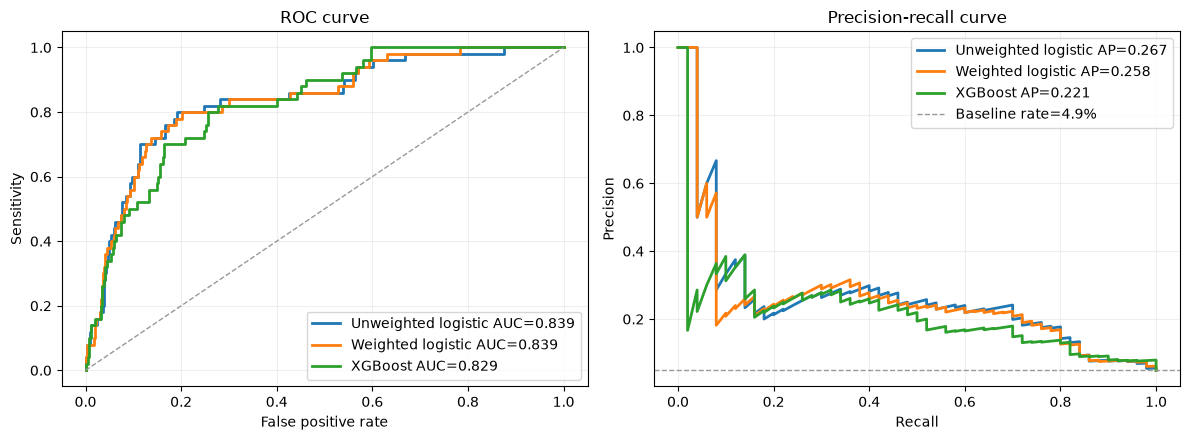

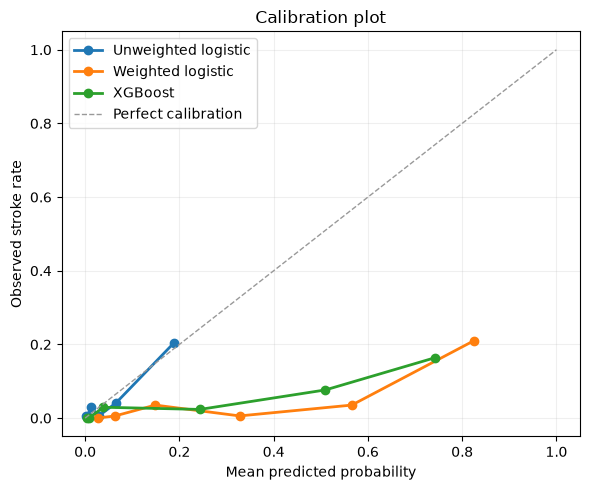

In [97]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name, (_, scores) in model_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    axes[0].plot(fpr, tpr, label=f"{name} AUC={roc_auc_score(y_test, scores):.3f}", linewidth=2)
axes[0].plot([0, 1], [0, 1], color="#999999", linestyle="--", linewidth=1)
axes[0].set_title("ROC curve")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("Sensitivity")
axes[0].legend()
axes[0].grid(alpha=0.2)

for name, (_, scores) in model_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    axes[1].plot(recall, precision, label=f"{name} AP={average_precision_score(y_test, scores):.3f}", linewidth=2)
axes[1].axhline(y_test.mean(), color="#999999", linestyle="--", linewidth=1, label=f"Baseline rate={y_test.mean():.1%}")
axes[1].set_title("Precision-recall curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for name, (_, scores) in model_scores.items():
    frac_pos, mean_pred = calibration_curve(y_test, scores, n_bins=6, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", linewidth=2, label=name)
ax.plot([0, 1], [0, 1], color="#999999", linestyle="--", linewidth=1, label="Perfect calibration")
ax.set_title("Calibration plot")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed stroke rate")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### Chapter 5 parking lot

- Tune hyperprameter of XGBoost with cross-validation rather than using one small hand-picked configuration.
- Calibrate XGBoost probabilities if it becomes the preferred model.


## 6. Threshold and outreach recommendation
For the operational recommendation, I use the unweighted logistic model. It performed best on PR-AUC, had the best Brier score, and is easiest to explain.

In [98]:
recommended_scores = unweighted_proba
recommended_model_name = "Unweighted logistic"
base_rate = y_test.mean()


def outreach_at_fraction_named(y_true, scores, fraction):
    n = len(y_true)
    k = max(1, int(np.ceil(n * fraction)))
    order = np.argsort(scores)[::-1]
    selected = order[:k]
    selected_true = np.asarray(y_true)[selected]
    true_positives = int(selected_true.sum())
    false_positives = int(k - true_positives)
    total_positives = int(np.asarray(y_true).sum())
    precision = true_positives / k
    recall = true_positives / total_positives if total_positives else np.nan
    return {
        "cutoff": f"Top {fraction:.1%}",
        "patients_called": int(k),
        "true_strokes_reached": true_positives,
        "false_positives": false_positives,
        "precision": precision,
        "recall": recall,
        "lift_vs_average": precision / base_rate if base_rate else np.nan,
        "min_score": float(scores[selected[-1]]),
    }


cutoffs = [0.01, 0.025, 0.05, 0.075, 0.10, 0.125, 0.15, 0.20, 0.25, 0.30]
outreach = pd.DataFrame([outreach_at_fraction_named(y_test.to_numpy(), recommended_scores, f) for f in cutoffs])

display(outreach)

top10 = outreach.loc[outreach["cutoff"] == "Top 10.0%"].iloc[0]
recommendation = (
    f"Use the {recommended_model_name} model to rank patients by predicted stroke risk. "
    f"As a starting point, call the top 10% of scored patients. "
    f"In the held-out test set, that means {int(top10['patients_called'])} calls and "
    f"{int(top10['true_strokes_reached'])} observed stroke cases reached. "
    f"Precision is {top10['precision']:.1%}, recall is {top10['recall']:.1%}, "
    f"and the called group has about {top10['lift_vs_average']:.1f}x the average stroke rate. "
    "If monthly capacity is tighter, use the top 5%; if the team can tolerate more false positives, expand toward 15% or 20%."
)
print(recommendation)

scored = pd.DataFrame(
    {
        "stroke": y_test.to_numpy(),
        "predicted_risk": recommended_scores,
    }
).sort_values("predicted_risk", ascending=False).reset_index(drop=True)

scored["patients_contacted"] = np.arange(1, len(scored) + 1)
scored["pct_patients_contacted"] = scored["patients_contacted"] / len(scored)
scored["cumulative_strokes"] = scored["stroke"].cumsum()
scored["pct_strokes_captured"] = scored["cumulative_strokes"] / scored["stroke"].sum()
scored["random_baseline"] = scored["pct_patients_contacted"]
scored["lift_at_k"] = scored["pct_strokes_captured"] / scored["pct_patients_contacted"]
scored["precision_at_k"] = scored["cumulative_strokes"] / scored["patients_contacted"]
scored["recall_at_k"] = scored["pct_strokes_captured"]


,cutoff,patients_called,true_strokes_reached,false_positives,precision,recall,lift_vs_average,min_score
0,Top 1.0%,11,4,7,0.363636,0.08,7.432727,0.322846
1,Top 2.5%,26,7,19,0.269231,0.14,5.503077,0.264586
2,Top 5.0%,52,14,38,0.269231,0.28,5.503077,0.214082
3,Top 7.5%,77,21,56,0.272727,0.42,5.574545,0.174771
4,Top 10.0%,103,26,77,0.252427,0.52,5.159612,0.150286
5,Top 12.5%,128,30,98,0.234375,0.60,4.790625,0.135932
6,Top 15.0%,154,35,119,0.227273,0.70,4.645455,0.116704
7,Top 20.0%,205,38,167,0.185366,0.76,3.788878,0.080091
8,Top 25.0%,256,40,216,0.156250,0.80,3.193750,0.062587
9,Top 30.0%,307,41,266,0.133550,0.82,2.729772,0.050662


Use the Unweighted logistic model to rank patients by predicted stroke risk. As a starting point, call the top 10% of scored patients. In the held-out test set, that means 103 calls and 26 observed stroke cases reached. Precision is 25.2%, recall is 52.0%, and the called group has about 5.2x the average stroke rate. If monthly capacity is tighter, use the top 5%; if the team can tolerate more false positives, expand toward 15% or 20%.


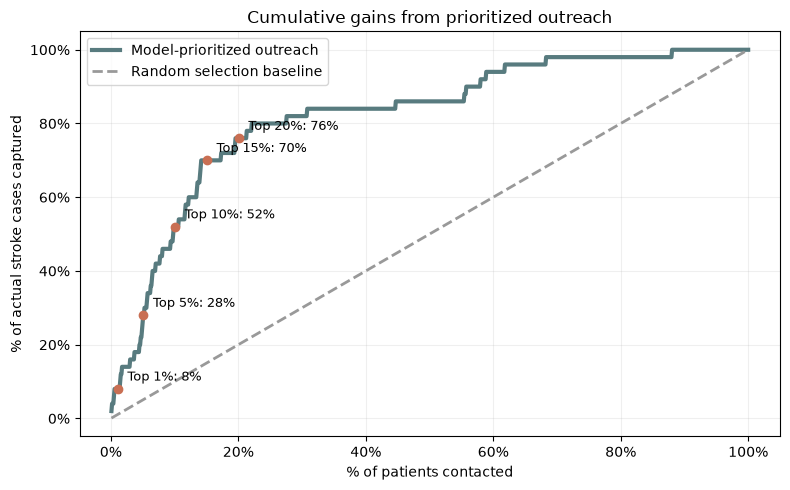

In [99]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    scored["pct_patients_contacted"],
    scored["pct_strokes_captured"],
    label="Model-prioritized outreach",
    color="#587B7F",
    linewidth=3,
)
ax.plot(
    scored["pct_patients_contacted"],
    scored["random_baseline"],
    label="Random selection baseline",
    color="#999999",
    linestyle="--",
    linewidth=2,
)
for frac in [0.01, 0.05, 0.10, 0.15, 0.20]:
    row = scored.iloc[int(np.ceil(len(scored) * frac)) - 1]
    ax.scatter(row["pct_patients_contacted"], row["pct_strokes_captured"], color="#C96F53", zorder=5)
    ax.annotate(
        f"Top {frac:.0%}: {row['pct_strokes_captured']:.0%}",
        (row["pct_patients_contacted"], row["pct_strokes_captured"]),
        textcoords="offset points",
        xytext=(7, 6),
        fontsize=9,
    )
ax.set_title("Cumulative gains from prioritized outreach")
ax.set_xlabel("% of patients contacted")
ax.set_ylabel("% of actual stroke cases captured")
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.yaxis.set_major_formatter(lambda y, pos: f"{y:.0%}")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()


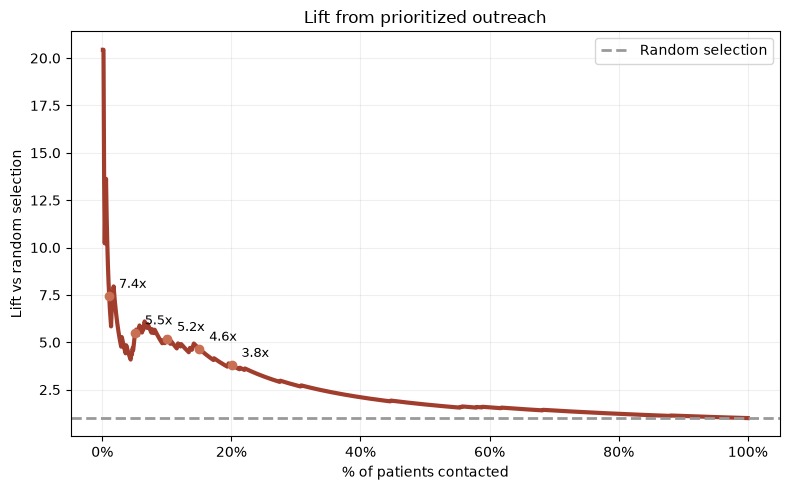

In [100]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    scored["pct_patients_contacted"],
    scored["lift_at_k"],
    color="#A13D2D",
    linewidth=3,
)
ax.axhline(1, color="#999999", linestyle="--", linewidth=2, label="Random selection")
for frac in [0.01, 0.05, 0.10, 0.15, 0.20]:
    row = scored.iloc[int(np.ceil(len(scored) * frac)) - 1]
    ax.scatter(row["pct_patients_contacted"], row["lift_at_k"], color="#C96F53", zorder=5)
    ax.annotate(
        f"{row['lift_at_k']:.1f}x",
        (row["pct_patients_contacted"], row["lift_at_k"]),
        textcoords="offset points",
        xytext=(7, 6),
        fontsize=9,
    )
ax.set_title("Lift from prioritized outreach")
ax.set_xlabel("% of patients contacted")
ax.set_ylabel("Lift vs random selection")
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()


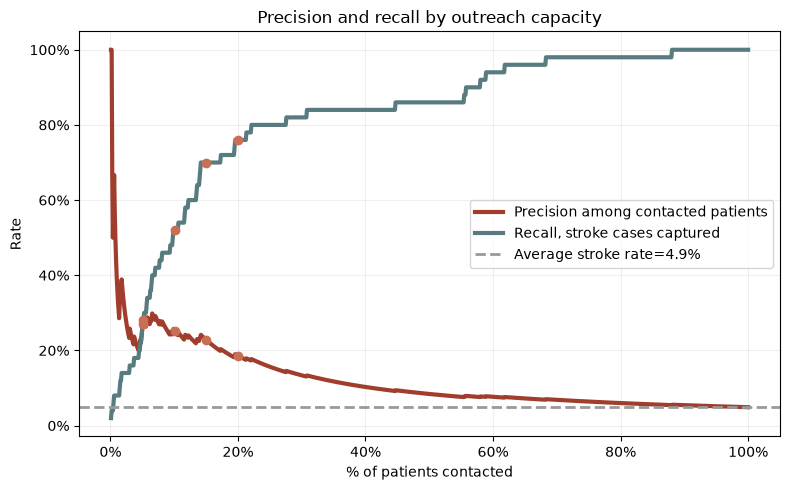

In [101]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    scored["pct_patients_contacted"],
    scored["precision_at_k"],
    label="Precision among contacted patients",
    color="#A13D2D",
    linewidth=3,
)
ax.plot(
    scored["pct_patients_contacted"],
    scored["recall_at_k"],
    label="Recall, stroke cases captured",
    color="#587B7F",
    linewidth=3,
)
ax.axhline(base_rate, color="#999999", linestyle="--", linewidth=2, label=f"Average stroke rate={base_rate:.1%}")
for frac in [0.05, 0.10, 0.15, 0.20]:
    row = scored.iloc[int(np.ceil(len(scored) * frac)) - 1]
    ax.scatter(row["pct_patients_contacted"], row["precision_at_k"], color="#C96F53", zorder=5)
    ax.scatter(row["pct_patients_contacted"], row["recall_at_k"], color="#C96F53", zorder=5)
ax.set_title("Precision and recall by outreach capacity")
ax.set_xlabel("% of patients contacted")
ax.set_ylabel("Rate")
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.yaxis.set_major_formatter(lambda y, pos: f"{y:.0%}")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()


### Chapter 6 parking lot
- get more operational/fianace infomation to add more constrains

## 7. Parking lot

Items I would investigate with more time:

- Validate clinical timing, including when glucose and BMI were measured relative to the stroke outcome.
- Try additional model families such as decision trees and random forests.
- Test fairness and subgroup performance. The `Other` gender group has only one record, and small subgroups need careful handling before deployment.
- Tune models more broadly, including validation-based feature selection for logistic regression and calibration methods.
- Define program capacity with operations. The best cutoff should reflect staffing capacity, expected contact rate, and the value of prevention visits.
